# NPC external validation — UNI2 A2 paired_v2 Hist2Pheno

Two HE slides, StarDist nuclei, **no cell-type ground truth**. StarDist detections were exported at probability 0.01. On both slides the histogram is flat from about 0.30 to 0.40 and then rises into the nucleus mode (peak near 0.75). Predictions below keep nuclei with **probability ≥ 0.40** and rebuild the k=8 neighborhood on that subset. The unfiltered run remains in the directory without the `_prob0.40` suffix.
This notebook applies the 2026-10-27 UNI2 retrain **A2** `best_mlp_gpu.pt` (fold 1; adjacent loss, L2→L1 NLL weight 2, spatial k=8 mean, no gate). Pooled OOF L2 macro AUROC on the training cohorts was 0.8894. The unfiltered A2 predictions stay in `pred_uni2_A2_bestmlp_paired_v2_seed42`. The published UNI maps stay in `Pred_visual_npc.ipynb`.

OME `PhysicalSize` is **0.465 µm/px**. A native 14 px crop is **6.51 µm**. UNI2 training crops are **7 µm** (14 px at 0.5 µm/px), so extraction rescales by `0.465/0.5 ≈ 0.930` and then takes a 14 px class token. StarDist centroids stay full-resolution HE pixels and are scaled with the image.

Outputs, separate from the UNI trees:

- `data/Visium/NPC/project_all_UNI2/{sample}/ImgEmbeddings_all_stardist/sc_pth_14_14/`
- `data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/{sample}/{sample}_stardist_pred.h5ad`

Run `CUDA_DEVICE=2 bash code/External_val/NPC/demo_uni2_A2.sh predict` on a free GPU, then run the cells. UNI2 `.pth` files are already under `project_all_UNI2`. There is no ROC.


## Run this A2 checkpoint

`demo.sh` is the UNI run (`patch_size=16`, `project_all_UNI`). This script applies the paired_v2 A2 weight. Pick a free GPU with `CUDA_DEVICE`. A finished sample is skipped when the checkpoint hash matches.

```bash
bash code/External_val/NPC/demo_uni2_A2.sh dry-run
CUDA_DEVICE=2 bash code/External_val/NPC/demo_uni2_A2.sh predict
# one slide: SAMPLE=20210809-C-AH4199551 CUDA_DEVICE=2 bash code/External_val/NPC/demo_uni2_A2.sh predict
```


In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams["pdf.fonttype"] = 42  # TrueType; PDF text stays editable
mpl.rcParams["ps.fonttype"] = 42


def save_figure(fig, path, *, dpi=None):
    """Write PDF (editable text) and a PNG preview. Call after the setup cell."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    dpi = int(SAVE_DPI if dpi is None else dpi)
    pdf = path.with_suffix(".pdf")
    png = path.with_suffix(".png")
    fig.savefig(pdf, format="pdf", bbox_inches="tight", facecolor="white", edgecolor="none")
    fig.savefig(png, format="png", dpi=dpi, bbox_inches="tight", facecolor="white", edgecolor="none")
    print(pdf)
    return pdf

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))

from Hist2Pheno_pkg.external_validation import ExternalCohort

CKPT = (
    REPO
    / "data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42"
    / "cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt"
)
_cohort = ExternalCohort(
    name="NPC",
    data_root=REPO / "data" / "Visium" / "NPC",
    repo=REPO,
    patch_size=14,
    method="UNI2",
    embedding_dirname="project_all_UNI2",
    pred_dirname="pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40",
    checkpoint=CKPT,
    project_tag="project_all_UNI2",
)
PRED_ROOT = _cohort.pred_root
composition_table = _cohort.composition_table
discover_samples = _cohort.discover_samples
geometry = _cohort.geometry
sample_paths = _cohort.sample_paths
ensure_l2_probs = _cohort.ensure_l2_probs
plot_spatial = _cohort.plot_spatial
plot_composition = _cohort.plot_composition
# Re-run the plot cell after changing these. Notebook display uses DPI; PNG uses SAVE_DPI; PDF is Type 42 vector.
SAVE_FIGURES = True
FIGSIZE = (17.2, 6.6)
DPI = 200
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.2
STAR_PROB_MIN = 0.30  # valley between the prob=0.01 tail and the nucleus mode
samples = discover_samples()
print(f"StarDist probability >= {STAR_PROB_MIN:.2f}")
print(f"checkpoint {CKPT.name} exists={CKPT.is_file()}")
print(f"pred root {PRED_ROOT}")
for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native14={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  embeddings: {p['emb']}")
    print(f"  pred exists: {p['pred'].is_file()}  {p['pred']}")


StarDist probability >= 0.30
checkpoint best_mlp_gpu.pt exists=True
pred root /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40
20210809-C-AH4199551  mpp=0.4651 µm/px  native14=6.51 µm  after rescale=7.0 µm  scale=0.9302
  embeddings: /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/project_all_UNI2/20210809-C-AH4199551/ImgEmbeddings_all_stardist/sc_pth_14_14
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/20210809-C-AH4199551/20210809-C-AH4199551_stardist_pred.h5ad
20210809-D-AJ3037946  mpp=0.4651 µm/px  native14=6.51 µm  after rescale=7.0 µm  scale=0.9302
  embeddings: /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/project_all_UNI2/20210809-D-AJ3037946/ImgEmbeddings_all_stardist/sc_pth_14_14
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/20210809-D-AJ3037946/20210809-D-AJ3037946_stardi

In [2]:
import pandas as pd
from IPython.display import Image, display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No UNI2 predictions yet for "
        + ", ".join(missing)
        + ". Run: CUDA_DEVICE=2 bash code/External_val/NPC/demo_uni2_A2.sh predict"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))



===== L1 =====


fraction                                 mean_conf  \
sample      20210809-C-AH4199551 20210809-D-AJ3037946 20210809-C-AH4199551   
class                                                                        
Epithelial                 0.831                0.758                0.731   
Immune                     0.146                0.224                0.537   
Endothelial                0.020                0.015                0.445   
Stromal                    0.002                0.004                0.381   
Neural                     0.001                  NaN                0.524   

                                                    n                       
sample      20210809-D-AJ3037946 20210809-C-AH4199551 20210809-D-AJ3037946  
class                                                                       
Epithelial                 0.709              72523.0              60842.0  
Immune                     0.538              12700.0              17987.0  
Endothelial                0.417               1779.0               1185.0  
Stromal                    0.404                197.0                288.0  
Neural                       NaN                 72.0                  NaN


===== L12 =====


fraction                                 mean_conf  \
sample      20210809-C-AH4199551 20210809-D-AJ3037946 20210809-C-AH4199551   
class                                                                        
Tumor                      0.523                0.483                0.672   
Myeloid                    0.253                0.287                0.510   
Epithelial                 0.200                0.178                0.508   
T_cell                     0.017                0.045                0.362   
Stromal                    0.004                0.005                0.345   
Endothelial                0.002                0.001                0.342   
B_Plasma                   0.000                0.001                0.314   

                                                    n                       
sample      20210809-D-AJ3037946 20210809-C-AH4199551 20210809-D-AJ3037946  
class                                                                       
Tumor                      0.623              45684.0              38810.0  
Myeloid                    0.459              22104.0              23048.0  
Epithelial                 0.469              17443.0              14281.0  
T_cell                     0.380               1468.0               3583.0  
Stromal                    0.330                337.0                392.0  
Endothelial                0.300                207.0                111.0  
B_Plasma                   0.309                 28.0                 77.0


===== L2 =====


fraction                       \
sample            20210809-C-AH4199551 20210809-D-AJ3037946   
class                                                         
Tumor                            0.422                0.291   
DC                               0.295                0.317   
Epithelial                       0.212                0.195   
DCIS                             0.041                0.138   
Neutrophil                       0.009                0.028   
CD4_T                            0.004                0.013   
Endothelial                      0.007                0.009   
Fibroblast                       0.000                0.003   
Myofibroblast                    0.002                0.000   
B_cell                           0.001                0.002   
Alveolar                         0.002                0.000   
Tregs                            0.000                0.001   
CD8_T                            0.001                0.001   
Injury_epithelial                0.001                0.000   
Stromal                          0.001                0.000   
NK                               0.000                  NaN   
Myoepithelial                    0.000                0.000   
Macrophage                       0.000                0.000   
Neural                           0.000                  NaN   
Plasma                           0.000                0.000   

                             mean_conf                       \
sample            20210809-C-AH4199551 20210809-D-AJ3037946   
class                                                         
Tumor                            0.541                0.473   
DC                               0.465                0.401   
Epithelial                       0.404                0.374   
DCIS                             0.426                0.497   
Neutrophil                       0.241                0.244   
CD4_T                            0.223                0.230   
Endothelial                      0.257                0.240   
Fibroblast                       0.230                0.258   
Myofibroblast                    0.276                0.216   
B_cell                           0.241                0.230   
Alveolar                         0.293                0.242   
Tregs                            0.252                0.264   
CD8_T                            0.240                0.217   
Injury_epithelial                0.338                0.365   
Stromal                          0.260                0.286   
NK                               0.278                  NaN   
Myoepithelial                    0.268                0.265   
Macrophage                       0.201                0.126   
Neural                           0.247                  NaN   
Plasma                           0.258                0.230   

                                     n                       
sample            20210809-C-AH4199551 20210809-D-AJ3037946  
class                                                        
Tumor                          36820.0              23384.0  
DC                             25775.0              25470.0  
Epithelial                     18545.0              15663.0  
DCIS                            3597.0              11115.0  
Neutrophil                       796.0               2216.0  
CD4_T                            351.0               1026.0  
Endothelial                      623.0                717.0  
Fibroblast                        36.0                269.0  
Myofibroblast                    164.0                 23.0  
B_cell                            97.0                143.0  
Alveolar                         137.0                  8.0  
Tregs                             23.0                108.0  
CD8_T                             52.0                 88.0  
Injury_epithelial                 80.0                  1.0  
Stromal                           44.0                 34.0  
NK            

[plot] 20210809-C-AH4199551  nuclei=87,271  neighbor=15.9px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.2  rows=HE+points
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-C-AH4199551_spatial_L1_L12_L2.pdf  save_dpi=300
[plot] 20210809-D-AJ3037946  nuclei=80,302  neighbor=15.9px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.2  rows=HE+points
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-D-AJ3037946_spatial_L1_L12_L2.pdf  save_dpi=300


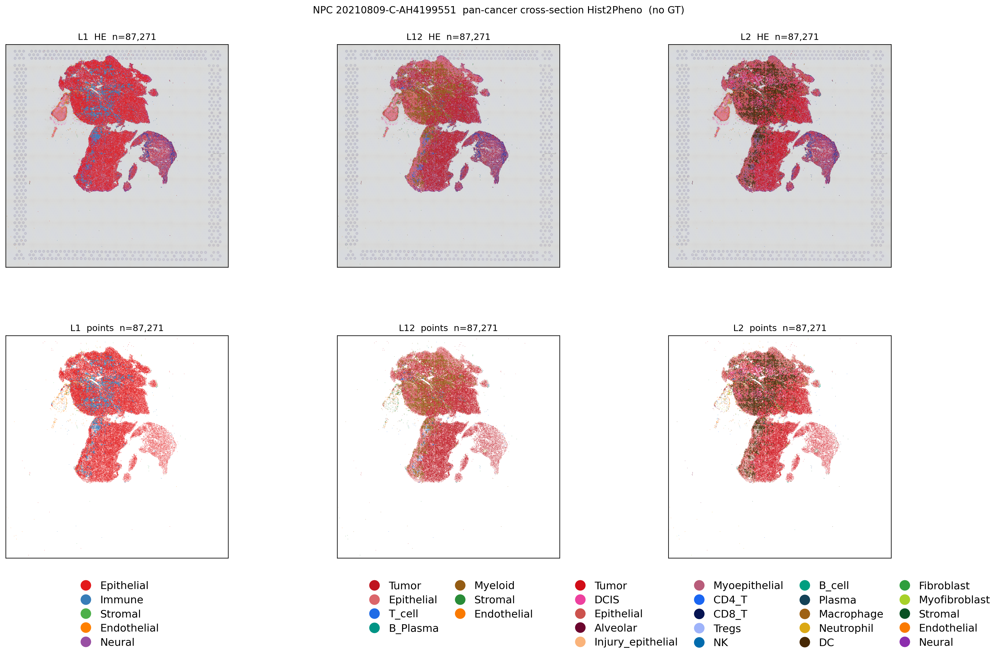

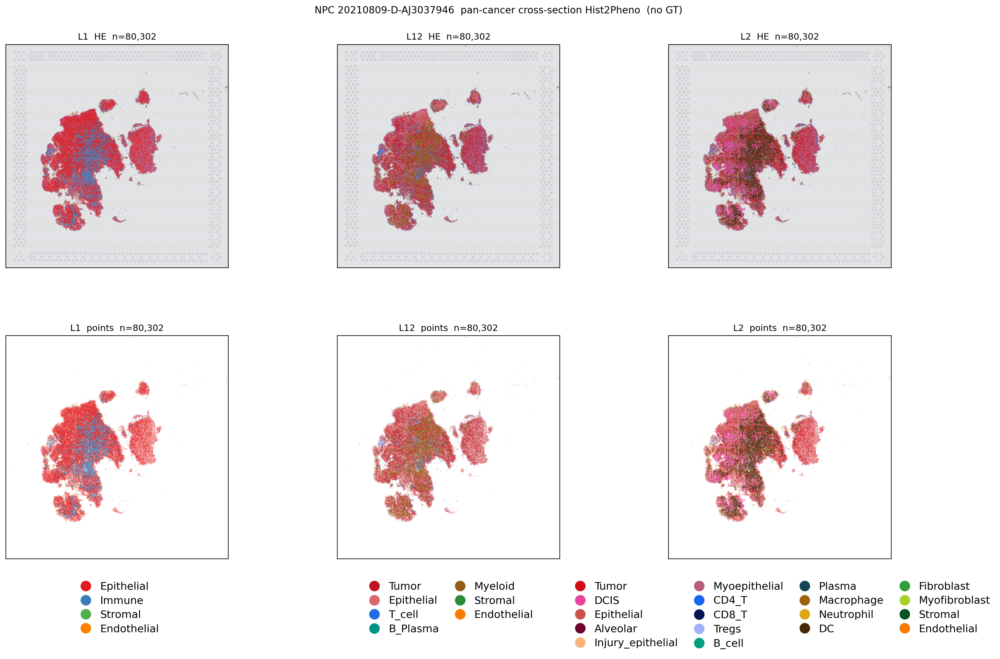

In [3]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/composition_L1.pdf  save_dpi=300
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/composition_L12.pdf  save_dpi=300
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/composition_L2.pdf  save_dpi=300


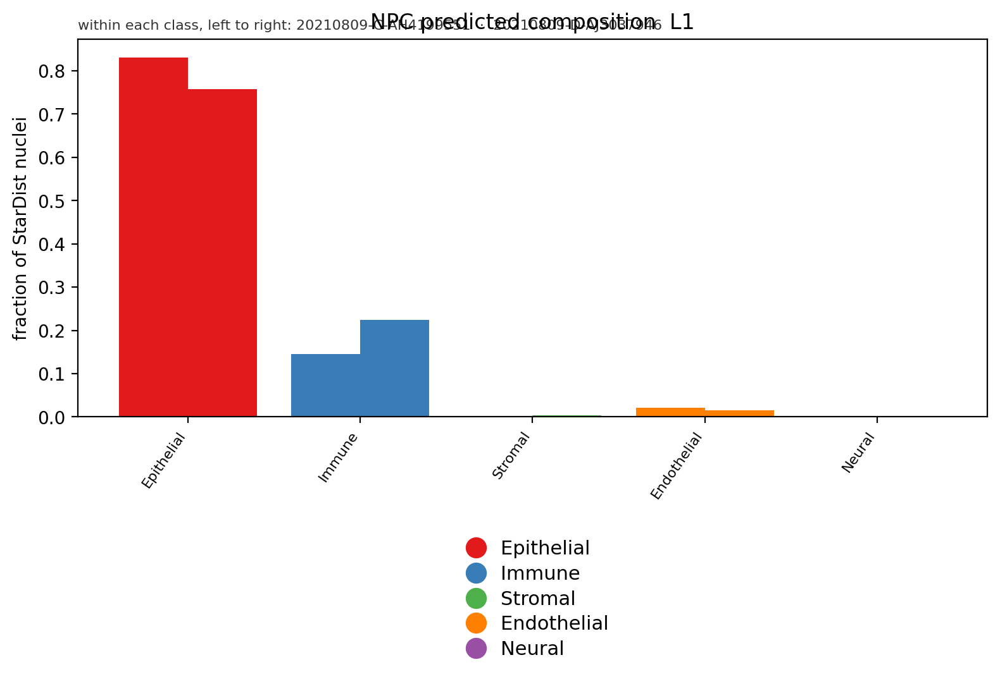

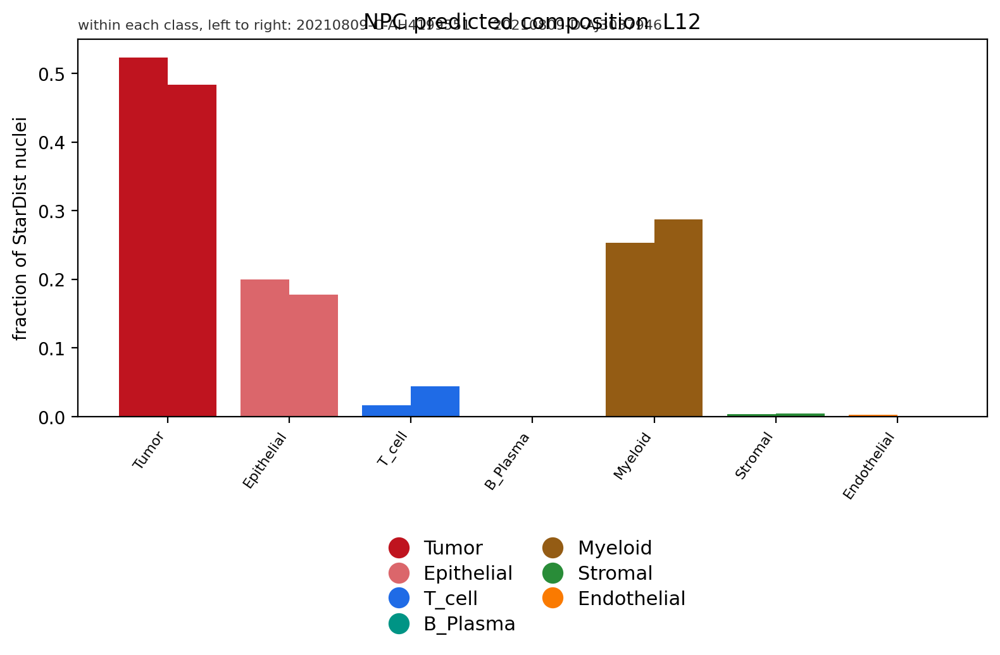

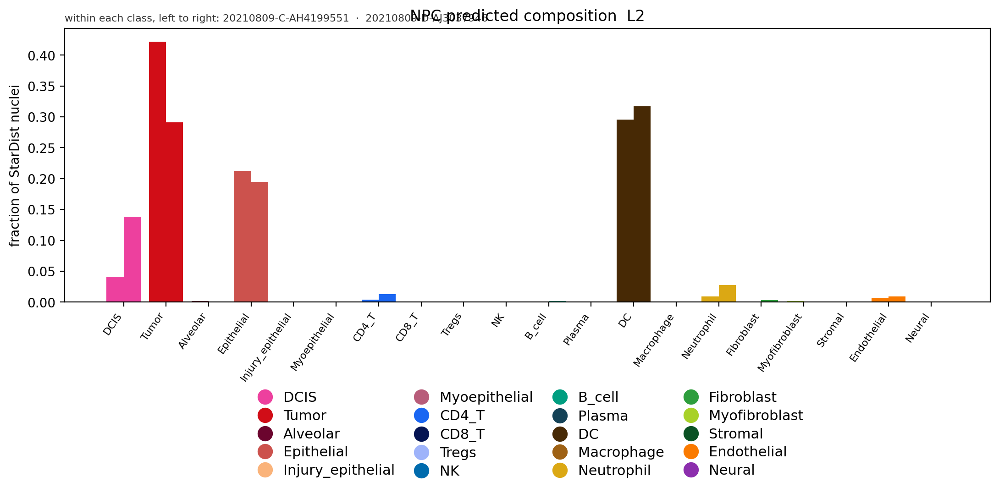

In [4]:
for fig in plot_composition(samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
    display(fig)
    plt.close(fig)


## Resolution from Visium spot to single cell

Same mapping as `Fig2_Fig3_panels.ipynb` (Fig. 3b). Each StarDist nucleus goes to the **nearest** Visium spot and is kept only inside that spot’s capture disc (`spot_diameter_fullres / 2`), via `Hist2Pheno_pkg/nuclei_to_spots.py`.

Three spatial panels: **single-nucleus L2**, **pseudo-spot** (majority predicted L2 in the disc), **cell2location** (argmax of the 7 abundances). Patient1 uses `Annotation/sp.obs.csv` (`AH4199551`); patient2 uses `Annotation/AJ_sp.obs.csv` (`AJ3037946`). The next cell stacks Hist2Pheno vs pseudo-spot vs cell2location on the same 7-type vocabulary.


cell2location ['sp.obs.csv', 'AJ_sp.obs.csv'] rows 2420 samples ['AH4199551', 'AJ3037946']
cell2location AH4199551: 1,331 / 1,331 in-tissue spots matched


,group,Hist2Pheno,pseudo_spot,cell2location
0,tumor,0.4219,0.4932,0.5282
1,normal,0.2566,0.2311,0.0594
2,fibroblast,0.0028,0.0083,0.1067
3,T,0.0051,0.0023,0.0624
4,Treg,0.0003,0.0008,0.0038
5,B,0.0012,0.0015,0.1803
6,Myeloid,0.3048,0.2560,0.0594
7,other,0.0073,0.0068,0.0000


NPC 20210809-C-AH4199551 (patient1): nuclei 87,271, in-tissue spots 1,331, pitch 214.0 px, capture radius 69.7 px, nuclei in a spot 32,471 / 87,271, spots with nuclei 1,324
/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-C-AH4199551_nuclei_vs_visium.pdf


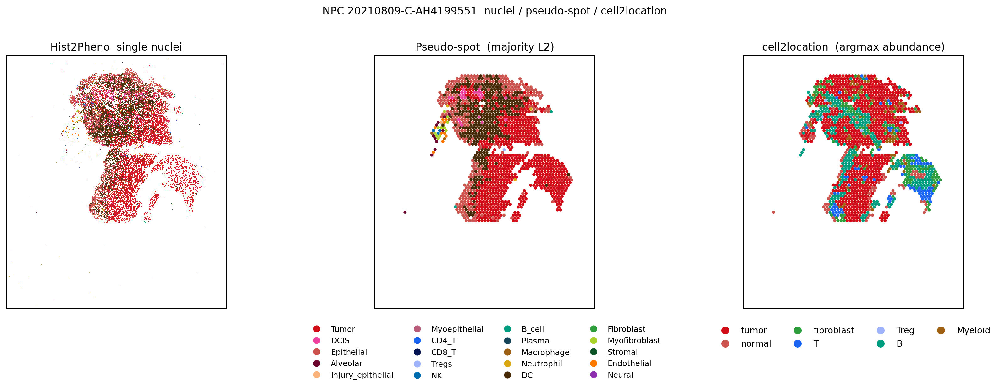

cell2location AJ3037946: 1,089 / 1,089 in-tissue spots matched


,group,Hist2Pheno,pseudo_spot,cell2location
0,tumor,0.2912,0.3392,0.2626
1,normal,0.3340,0.3143,0.0083
2,fibroblast,0.0041,0.0037,0.0882
3,T,0.0139,0.0092,0.0184
4,Treg,0.0013,0.0018,0.0037
5,B,0.0018,0.0000,0.5647
6,Myeloid,0.3448,0.3290,0.0542
7,other,0.0089,0.0028,0.0000


NPC 20210809-D-AJ3037946 (patient2): nuclei 80,302, in-tissue spots 1,089, pitch 214.0 px, capture radius 69.7 px, nuclei in a spot 30,072 / 80,302, spots with nuclei 1,088
/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-D-AJ3037946_nuclei_vs_visium.pdf


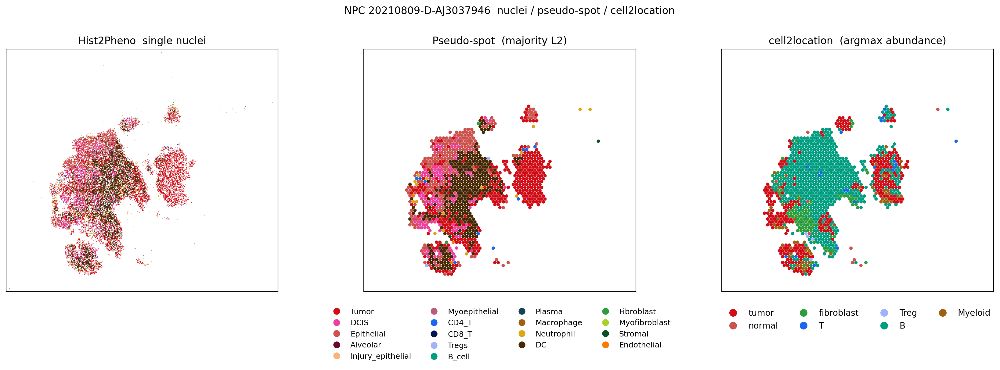

In [5]:
import json

import anndata as ad
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Circle
from scipy.spatial import cKDTree

from Hist2Pheno_pkg.nuclei_to_spots import nuclei_to_spots
from Hist2Pheno_pkg.plotting_palettes import get_palette

L2_PALETTE = get_palette("pancancer", "fine")
L2_NAMES = list(L2_PALETTE)
SAMPLE_TO_VISIUM = {
    "20210809-C-AH4199551": "patient1",
    "20210809-D-AJ3037946": "patient2",
}
SAMPLE_TO_C2L = {
    "20210809-C-AH4199551": "AH4199551",
    "20210809-D-AJ3037946": "AJ3037946",
}
NPC_DATA = REPO / "data" / "Visium" / "NPC"
C2L_FILES = [
    NPC_DATA / "Annotation" / "sp.obs.csv",
    NPC_DATA / "Annotation" / "AJ_sp.obs.csv",
]
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# cell2location types, coloured like the matching pan-cancer L2 classes.
C2L_TYPES = ("tumor", "normal", "fibroblast", "T", "Treg", "B", "Myeloid")
C2L_COLOR = {
    "tumor": L2_PALETTE["Tumor"],
    "normal": L2_PALETTE["Epithelial"],
    "fibroblast": L2_PALETTE["Fibroblast"],
    "T": L2_PALETTE["CD4_T"],
    "Treg": L2_PALETTE["Tregs"],
    "B": L2_PALETTE["B_cell"],
    "Myeloid": L2_PALETTE["Macrophage"],
    "other": (0.62, 0.62, 0.62, 1.0),
}
STACK_ORDER = C2L_TYPES + ("other",)
L2_TO_C2L = {
    "Tumor": "tumor",
    "Epithelial": "normal",
    "Alveolar": "normal",
    "Injury_epithelial": "normal",
    "DCIS": "normal",
    "Myoepithelial": "normal",
    "Fibroblast": "fibroblast",
    "Myofibroblast": "fibroblast",
    "Stromal": "fibroblast",
    "CD4_T": "T",
    "CD8_T": "T",
    "NK": "T",
    "Tregs": "Treg",
    "B_cell": "B",
    "Plasma": "B",
    "Macrophage": "Myeloid",
    "DC": "Myeloid",
    "Neutrophil": "Myeloid",
}


def map_l2(names) -> np.ndarray:
    return np.array([L2_TO_C2L.get(str(n), "other") for n in names], dtype=object)


def group_fraction(labels: np.ndarray) -> pd.Series:
    vc = pd.Series(labels).value_counts(normalize=True)
    return pd.Series({k: float(vc.get(k, 0.0)) for k in STACK_ORDER})


def legend_handles(names, palette, markersize=8):
    return [
        Line2D(
            [0], [0], marker="o", color="none",
            markerfacecolor=palette[name][:3] if not isinstance(palette[name], str) else palette[name],
            markeredgecolor="none", markersize=markersize, label=name,
        )
        for name in names
        if name in palette
    ]


def draw_spot_circles(ax, xy, labels, radius, palette, order):
    patches, colors = [], []
    labels = np.asarray(labels)
    for name in order:
        hit = labels == name
        if not np.any(hit):
            continue
        col = palette[name]
        rgb = col[:3] if not isinstance(col, str) else col
        for x, y in np.asarray(xy)[hit]:
            patches.append(Circle((x, y), radius))
            colors.append(rgb)
    if patches:
        ax.add_collection(PatchCollection(patches, facecolors=colors, edgecolors="none"))


missing = [p for p in C2L_FILES if not p.is_file()]
if missing:
    raise FileNotFoundError(missing)
c2l_obs = pd.concat([pd.read_csv(p, index_col=0) for p in C2L_FILES], axis=0)
c2l_obs.index = c2l_obs.index.astype(str)
print(
    "cell2location",
    [p.name for p in C2L_FILES],
    "rows",
    len(c2l_obs),
    "samples",
    sorted(c2l_obs["sample"].astype(str).unique()),
)

nucleus_s = max(0.12, (float(MARKER_PX) * 72.0 / float(DPI)) ** 2 * 0.35)
spot_maps = {}

for sample in samples:
    visium_id = SAMPLE_TO_VISIUM.get(sample)
    if visium_id is None:
        print(f"[skip] {sample}: no patient1/patient2 Visium folder mapping")
        continue
    npc_dir = NPC_DATA / visium_id
    pred_path = sample_paths(sample)["pred"]
    if not pred_path.is_file():
        raise FileNotFoundError(pred_path)
    scale = json.loads((npc_dir / "scalefactors_json.json").read_text())
    radius_px = float(scale["spot_diameter_fullres"]) / 2
    pos = pd.read_csv(
        npc_dir / "tissue_positions_list.csv",
        header=None,
        names=["barcode", "in_tissue", "array_row", "array_col", "pxl_row", "pxl_col"],
    )
    pos = pos.loc[pos["in_tissue"] == 1].reset_index(drop=True)
    pos["barcode"] = pos["barcode"].astype(str)
    spot_xy = pos[["pxl_col", "pxl_row"]].to_numpy(dtype=np.float64)
    pitch_px = float(np.median(cKDTree(spot_xy).query(spot_xy, k=2)[0][:, 1]))
    npc = ad.read_h5ad(pred_path)
    npc_xy = np.asarray(npc.obsm["spatial_HE"], dtype=np.float64)
    npc_lab = npc.obs["pred_CT"].astype(str).to_numpy()
    captured = nuclei_to_spots(
        npc_xy, spot_xy, radius_px, shape="circle",
        labels=npc_lab, class_names=L2_NAMES,
    )
    counts = captured["n_nuclei"]
    used = counts > 0
    npc_spots = pos.loc[used].copy()
    npc_spots["pixel_x"] = spot_xy[used, 0]
    npc_spots["pixel_y"] = spot_xy[used, 1]
    npc_spots["n_nuclei"] = counts[used]
    npc_spots["dominant_l2"] = captured["dominant"][used]
    npc_spots["dominant_group"] = map_l2(npc_spots["dominant_l2"])
    for i, name in enumerate(L2_NAMES):
        npc_spots[f"n_{name}"] = captured["class_counts"][used, i]
        npc_spots[f"fraction_{name}"] = captured["class_counts"][used, i] / counts[used]
    npc_spots.to_csv(fig_dir / f"{sample}_visium_composition.csv", index=False)

    nuc_group = map_l2(npc_lab)
    h2p_frac = group_fraction(nuc_group)
    pseudo_frac = group_fraction(npc_spots["dominant_group"].to_numpy())

    c2l_id = SAMPLE_TO_C2L.get(sample)
    c2l_xy = c2l_lab = None
    c2l_frac = None
    if c2l_id is not None:
        sub = c2l_obs.loc[c2l_obs["sample"].astype(str) == str(c2l_id)].copy()
        hit = pos["barcode"].isin(sub.index)
        aligned = sub.reindex(pos.loc[hit, "barcode"])
        raw = aligned[list(C2L_TYPES)].to_numpy(dtype=np.float64)
        ok = np.isfinite(raw).all(axis=1) & (raw.sum(axis=1) > 0)
        raw = raw[ok]
        c2l_xy = spot_xy[hit.to_numpy()][ok]
        c2l_lab = np.array(C2L_TYPES)[np.argmax(raw, axis=1)]
        c2l_frac = group_fraction(c2l_lab)
        print(
            f"cell2location {c2l_id}: {int(ok.sum()):,} / {int(hit.sum()):,} "
            f"in-tissue spots matched"
        )

    spot_maps[sample] = {
        "h2p": h2p_frac,
        "pseudo": pseudo_frac,
        "c2l": c2l_frac,
        "n_nuc": len(npc_lab),
        "n_spot": int(used.sum()),
        "n_c2l": 0 if c2l_lab is None else int(len(c2l_lab)),
    }
    frac = pd.DataFrame(
        {
            "group": list(STACK_ORDER),
            "Hist2Pheno": [h2p_frac[k] for k in STACK_ORDER],
            "pseudo_spot": [pseudo_frac[k] for k in STACK_ORDER],
            "cell2location": [
                float(c2l_frac[k]) if c2l_frac is not None else np.nan
                for k in STACK_ORDER
            ],
        }
    )
    frac.to_csv(fig_dir / f"{sample}_nuclei_vs_visium_fraction.csv", index=False)
    display(frac.round(4))
    print(
        f"NPC {sample} ({visium_id}): nuclei {len(npc_xy):,}, "
        f"in-tissue spots {len(spot_xy):,}, pitch {pitch_px:.1f} px, "
        f"capture radius {radius_px:.1f} px, "
        f"nuclei in a spot {int(captured['inside'].sum()):,} / {len(npc_xy):,}, "
        f"spots with nuclei {int(used.sum()):,}"
    )

    spot_draw_radius = 0.50 * pitch_px
    fig, axes = plt.subplots(1, 3, figsize=(16.8, 5.6), dpi=DPI)
    axes[0].set_title("Hist2Pheno  single nuclei")
    for name in L2_NAMES:
        mask = npc_lab == name
        if np.any(mask):
            axes[0].scatter(
                npc_xy[mask, 0], npc_xy[mask, 1], s=nucleus_s,
                c=[L2_PALETTE[name]], linewidths=0, rasterized=True,
            )
    draw_spot_circles(
        axes[1], spot_xy[used], npc_spots["dominant_l2"].to_numpy(),
        spot_draw_radius, L2_PALETTE, L2_NAMES,
    )
    axes[1].set_title("Pseudo-spot  (majority L2)")
    if c2l_xy is None:
        axes[2].text(0.5, 0.5, "no cell2location\nfor this slide", ha="center", va="center")
        axes[2].set_title("cell2location")
    else:
        draw_spot_circles(
            axes[2], c2l_xy, c2l_lab, spot_draw_radius, C2L_COLOR, C2L_TYPES,
        )
        axes[2].set_title("cell2location  (argmax abundance)")
    pad = pitch_px
    for ax in axes:
        ax.set_xlim(npc_xy[:, 0].min() - pad, npc_xy[:, 0].max() + pad)
        ax.set_ylim(npc_xy[:, 1].max() + pad, npc_xy[:, 1].min() - pad)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
    present_l2 = [
        n for n in L2_NAMES
        if n in set(npc_lab) or n in set(npc_spots["dominant_l2"].astype(str))
    ]
    axes[1].legend(
        handles=legend_handles(present_l2, L2_PALETTE),
        frameon=False, fontsize=9, loc="upper center",
        bbox_to_anchor=(0.5, -0.04), ncol=4,
    )
    if c2l_lab is not None:
        present_c2l = [n for n in C2L_TYPES if n in set(c2l_lab)]
        axes[2].legend(
            handles=legend_handles(present_c2l, C2L_COLOR, markersize=9),
            frameon=False, fontsize=10, loc="upper center",
            bbox_to_anchor=(0.5, -0.04), ncol=4,
        )
    fig.suptitle(f"NPC {sample}  nuclei / pseudo-spot / cell2location", fontsize=12, y=1.02)
    fig.tight_layout()
    fig.subplots_adjust(bottom=0.16)
    if SAVE_FIGURES:
        save_figure(fig, fig_dir / f"{sample}_nuclei_vs_visium.pdf")
    display(fig)
    plt.close(fig)


### Stacked composition (same 7 types)

All three bars are **class proportions** on the same 7 cell2location types. Hist2Pheno = fraction of nuclei after mapping L2 → these types. Pseudo-spot = fraction of spots by majority mapped L2. cell2location = fraction of spots after converting per-spot abundances to a class (`argmax`). `other` is Endothelial / Neural (Hist2Pheno only).


/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/NPC_hist2pheno_pseudospot_cell2location_stacked.pdf


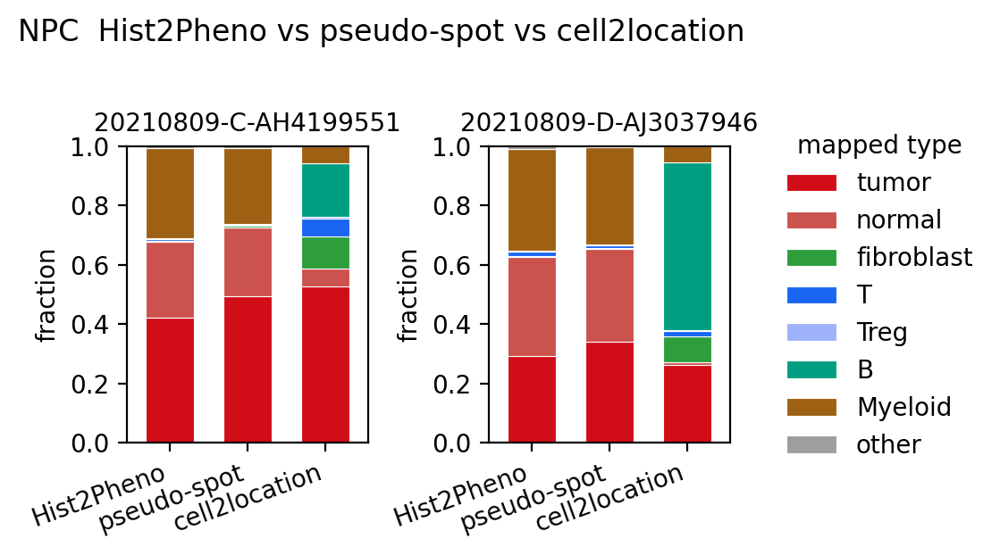

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/NPC_hist2pheno_pseudospot_cell2location_stacked.csv


sample     20210809-C-AH4199551                            \
method               Hist2Pheno cell2location pseudo-spot   
group                                                       
B                         0.001         0.180       0.002   
Myeloid                   0.305         0.059       0.256   
T                         0.005         0.062       0.002   
Treg                      0.000         0.004       0.001   
fibroblast                0.003         0.107       0.008   
normal                    0.257         0.059       0.231   
other                     0.007         0.000       0.007   
tumor                     0.422         0.528       0.493   

sample     20210809-D-AJ3037946                            
method               Hist2Pheno cell2location pseudo-spot  
group                                                      
B                         0.002         0.565       0.000  
Myeloid                   0.345         0.054       0.329  
T                         0.014         0.018       0.009  
Treg                      0.001         0.004       0.002  
fibroblast                0.004         0.088       0.004  
normal                    0.334         0.008       0.314  
other                     0.009         0.000       0.003  
tumor                     0.291         0.263       0.339

In [6]:
# 100% stacked class proportions: Hist2Pheno nuclei vs pseudo-spot majority vs cell2location argmax.
# Groups are the 7 cell2location types (+ other). Patient1: sp.obs.csv; patient2: AJ_sp.obs.csv.
methods = ("Hist2Pheno", "pseudo-spot", "cell2location")
method_key = {"Hist2Pheno": "h2p", "pseudo-spot": "pseudo", "cell2location": "c2l"}
samples_plot = [s for s in samples if s in spot_maps]
n_panel = max(len(samples_plot), 1)
fig, axes = plt.subplots(
    1, n_panel, figsize=(1.2 * n_panel + 1.8, 3.0), dpi=DPI, squeeze=False,
)
axes = axes[0]
for ax, sample in zip(axes, samples_plot):
    rec = spot_maps[sample]
    x = np.arange(len(methods))
    bottom = np.zeros(len(methods))
    for grp in STACK_ORDER:
        vals = []
        for m in methods:
            ser = rec[method_key[m]]
            vals.append(float(ser[grp]) if ser is not None else 0.0)
        vals = np.asarray(vals, dtype=float)
        if np.allclose(vals, 0.0):
            continue
        ax.bar(
            x, vals, bottom=bottom, width=0.62,
            color=C2L_COLOR[grp][:3], edgecolor="white", linewidth=0.4, label=grp,
        )
        bottom = bottom + vals
    ax.set_xticks(x)
    ax.set_xticklabels(methods, rotation=20, ha="right")
    ax.set_ylim(0, 1)
    ax.set_ylabel("fraction")
    extra = ""
    if rec["c2l"] is None:
        extra = "  (no cell2location)"
        ax.text(2, 0.5, "n/a", ha="center", va="center", fontsize=9, color="#888888")
    ax.set_title(f"{sample}{extra}", fontsize=10)
    ax.set_xlim(-0.55, 2.55)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="center left", bbox_to_anchor=(1.01, 0.5),
    frameon=False, fontsize=10, title="mapped type",
)
fig.suptitle("NPC  Hist2Pheno vs pseudo-spot vs cell2location", fontsize=12, y=1.02)
fig.tight_layout()
if SAVE_FIGURES:
    save_figure(fig, fig_dir / "NPC_hist2pheno_pseudospot_cell2location_stacked.pdf")
display(fig)
plt.close(fig)

rows = []
for sample, rec in spot_maps.items():
    for method, key in method_key.items():
        ser = rec[key]
        if ser is None:
            continue
        for grp in STACK_ORDER:
            rows.append(
                {"sample": sample, "method": method, "group": grp, "fraction": float(ser[grp])}
            )
stack_tab = pd.DataFrame(rows)
stack_path = fig_dir / "NPC_hist2pheno_pseudospot_cell2location_stacked.csv"
stack_tab.to_csv(stack_path, index=False)
print(stack_path)
display(stack_tab.pivot_table(index="group", columns=["sample", "method"], values="fraction").round(3))


## TLS annotation (patient1)

Expert Visium TLS barcodes in `data/Visium/NPC/Annotation/TLS_spot_label.csv` (36 spots on `AH4199551` / `20210809-C-AH4199551`). Each barcode is mapped through `patient1/tissue_positions_list.csv`. A Gaussian-smoothed capture disc around those spots gives a **smooth outline** of each TLS focus. **Only the three left-side foci are kept** (the two lower-right clusters are dropped). The zoom box is the bounding rectangle of the kept spots plus padding. Overview: black outline only. Zoom: black outline + Visium spots. Then Hist2Pheno L1 / L12 / L2 inside that zoom.


TLS foci: 5 total, keep 3 leftmost (26 / 36 spots)
TLS 20210809-C-AH4199551: 26 spots, 3 smooth foci, pitch 214.0 px, zoom [5489:7896]×[6472:10755]  1120×1992 µm
/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-C-AH4199551_TLS_HE_overview_zoom.pdf


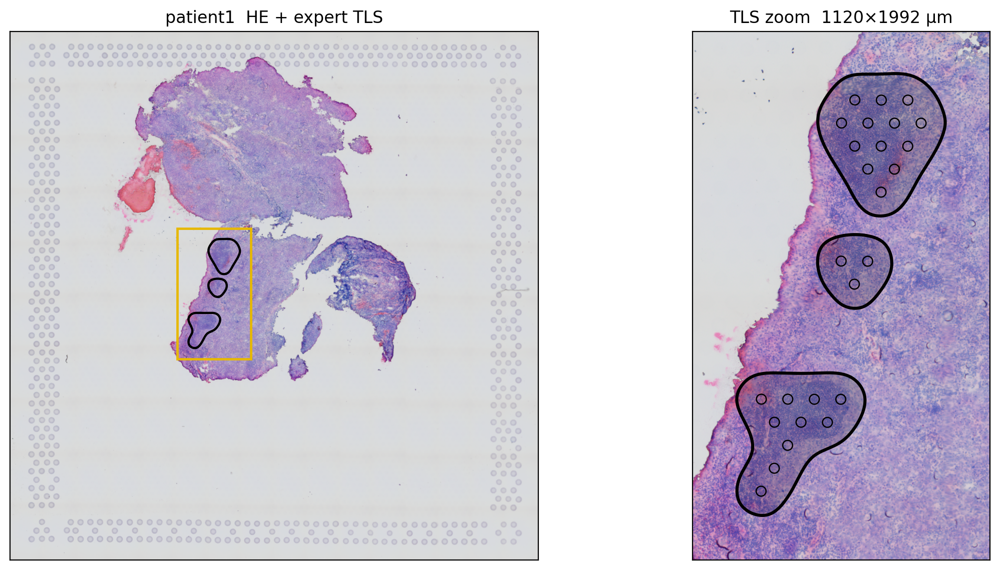

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-C-AH4199551_TLS_ROI_spatial_L1_L12_L2.pdf


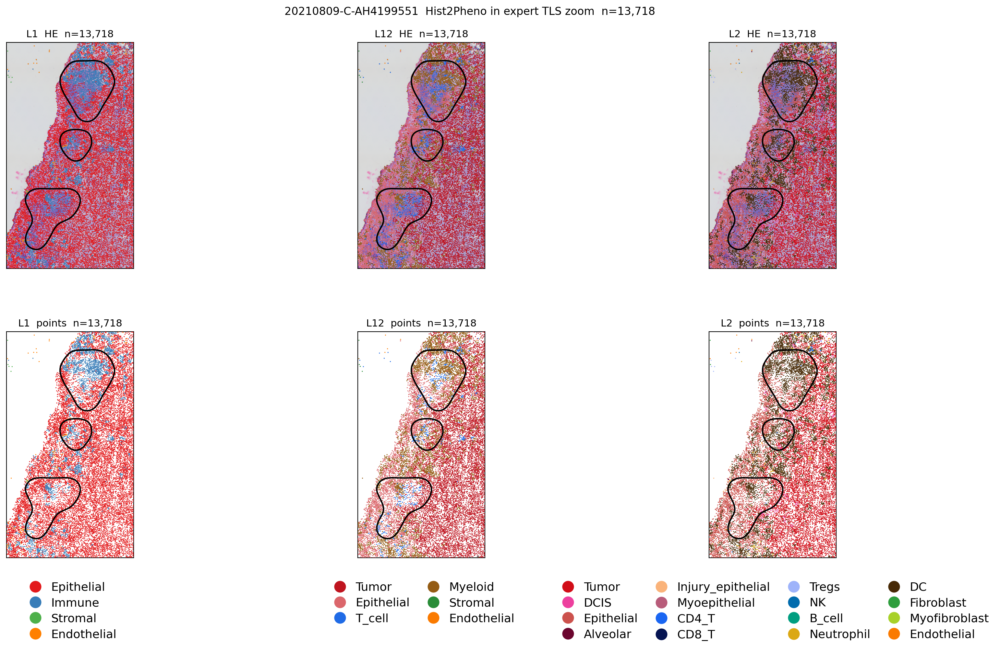

In [7]:
import json

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle
from scipy.interpolate import splprep, splev
from scipy.ndimage import gaussian_filter
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree, distance_matrix
from skimage.draw import disk
from skimage.measure import find_contours

from Hist2Pheno_pkg.panel_figures import (
    crop_he_rectangle,
    nuclei_in_rectangle,
    plot_roi_pred_spatial,
)

TLS_SAMPLE = "20210809-C-AH4199551"
NPC_DATA = REPO / "data" / "Visium" / "NPC"
TLS_PATH = NPC_DATA / "Annotation" / "TLS_spot_label.csv"
VISIUM_DIR = NPC_DATA / "patient1"
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

TLS_EDGE = "black"
TLS_FILL = (0.0, 0.0, 0.0, 0.16)
ROI_BOX = "#E6B800"
PAD_PITCH = 2.6
N_KEEP_LEFT = 3


def load_tls_xy(tls_path, visium_dir):
    raw = pd.read_csv(tls_path)
    barcodes = raw.iloc[:, -1].astype(str).tolist()
    pos = pd.read_csv(
        visium_dir / "tissue_positions_list.csv",
        header=None,
        names=["barcode", "in_tissue", "array_row", "array_col", "pxl_row", "pxl_col"],
    )
    pos["barcode"] = pos["barcode"].astype(str)
    hit = pos.set_index("barcode").reindex(barcodes)
    if hit["pxl_row"].isna().any():
        missing = hit.index[hit["pxl_row"].isna()].tolist()
        raise KeyError(f"TLS barcodes not in tissue_positions: {missing[:8]}")
    xy = hit[["pxl_col", "pxl_row"]].to_numpy(dtype=np.float64)
    in_t = pos.loc[pos["in_tissue"] == 1, ["pxl_col", "pxl_row"]].to_numpy(dtype=np.float64)
    pitch = float(np.median(cKDTree(in_t).query(in_t, k=2)[0][:, 1]))
    scale = json.loads((visium_dir / "scalefactors_json.json").read_text())
    spot_r = float(scale["spot_diameter_fullres"]) / 2.0
    return xy, np.asarray(barcodes), pitch, spot_r


def keep_leftmost_foci(xy, pitch, n_keep=3, link=2.2):
    """Drop the lower-right TLS clusters; keep the n leftmost connected foci."""
    labels = connected_components(distance_matrix(xy, xy) < link * pitch)[1]
    means = np.array([xy[labels == i, 0].mean() for i in range(int(labels.max()) + 1)])
    keep_ids = set(np.argsort(means)[: int(n_keep)].tolist())
    mask = np.isin(labels, list(keep_ids))
    print(
        f"TLS foci: {int(labels.max()) + 1} total, keep {n_keep} leftmost "
        f"({int(mask.sum())} / {len(xy)} spots)"
    )
    return mask


def spline_closed(poly, n=360, s_scale=12.0):
    p = np.asarray(poly, dtype=np.float64)
    if len(p) < 4:
        return p
    if np.linalg.norm(p[0] - p[-1]) > 1e-6:
        p = np.vstack([p, p[0]])
    step = np.sqrt(((p[1:] - p[:-1]) ** 2).sum(axis=1))
    p = p[np.concatenate([[True], step > 1e-3])]
    if len(p) < 4:
        return poly
    tck, _ = splprep([p[:, 0], p[:, 1]], s=s_scale * len(p), per=True, k=3)
    u = np.linspace(0.0, 1.0, n, endpoint=False)
    xs, ys = splev(u, tck)
    return np.column_stack([xs, ys])


def tls_smooth_contours(xy, disk_r, sigma, level=0.22, step=None):
    pad = float(disk_r + 4.0 * sigma)
    origin = xy.min(axis=0) - pad
    extent = xy.max(axis=0) + pad
    step = float(max(6.0, disk_r / 10.0) if step is None else step)
    w = int(np.ceil((extent[0] - origin[0]) / step))
    h = int(np.ceil((extent[1] - origin[1]) / step))
    mask = np.zeros((h, w), dtype=np.float32)
    rad = disk_r / step
    for x, y in xy:
        rr, cc = disk(((y - origin[1]) / step, (x - origin[0]) / step), rad, shape=mask.shape)
        mask[rr, cc] = 1.0
    mask = gaussian_filter(mask, sigma=sigma / step)
    out = []
    for contour in find_contours(mask, float(level)):
        xs = contour[:, 1] * step + origin[0]
        ys = contour[:, 0] * step + origin[1]
        out.append(spline_closed(np.column_stack([xs, ys])))
    return out


def draw_tls(
    ax,
    contours,
    spots=None,
    spot_r=None,
    local=(0.0, 0.0),
    lw=2.0,
    fill=False,
):
    x0, y0 = local
    for poly in contours:
        if fill:
            ax.fill(
                poly[:, 0] - x0,
                poly[:, 1] - y0,
                facecolor=TLS_FILL,
                edgecolor="none",
                zorder=4,
            )
        ax.plot(
            poly[:, 0] - x0,
            poly[:, 1] - y0,
            color=TLS_EDGE,
            lw=lw,
            solid_capstyle="round",
            zorder=5,
        )
    if spots is not None:
        ax.scatter(
            spots[:, 0] - x0,
            spots[:, 1] - y0,
            s=28 if spot_r is None else (spot_r * 72.0 / float(DPI)) ** 2 * 0.08,
            facecolors="none",
            edgecolors=TLS_EDGE,
            linewidths=0.9,
            zorder=6,
        )


tls_xy, tls_bc, pitch_px, spot_r_px = load_tls_xy(TLS_PATH, VISIUM_DIR)
keep = keep_leftmost_foci(tls_xy, pitch_px, n_keep=N_KEEP_LEFT)
tls_xy, tls_bc = tls_xy[keep], tls_bc[keep]
contours = tls_smooth_contours(tls_xy, disk_r=0.70 * pitch_px, sigma=0.45 * pitch_px)
paths = sample_paths(TLS_SAMPLE)
g = geometry(TLS_SAMPLE)
pad = PAD_PITCH * pitch_px
x0 = max(0.0, float(tls_xy[:, 0].min() - pad))
y0 = max(0.0, float(tls_xy[:, 1].min() - pad))
thumb, full_w, full_h = _cohort._he_thumbnail(paths["he"], max_side=HE_MAX_SIDE)
x1 = min(float(full_w), float(tls_xy[:, 0].max() + pad))
y1 = min(float(full_h), float(tls_xy[:, 1].max() + pad))
w_um = (x1 - x0) * g["mpp_um"]
h_um = (y1 - y0) * g["mpp_um"]
print(
    f"TLS {TLS_SAMPLE}: {len(tls_bc)} spots, {len(contours)} smooth foci, "
    f"pitch {pitch_px:.1f} px, zoom [{x0:.0f}:{x1:.0f}]×[{y0:.0f}:{y1:.0f}]  "
    f"{w_um:.0f}×{h_um:.0f} µm"
)

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.8), dpi=DPI)
axes[0].imshow(thumb, extent=(0, full_w, full_h, 0), interpolation="bilinear")
draw_tls(axes[0], contours, fill=False, lw=1.6)
axes[0].add_patch(
    Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=ROI_BOX, lw=1.7, zorder=7)
)
axes[0].set_title("patient1  HE + expert TLS")
axes[0].set_xlim(0, full_w)
axes[0].set_ylim(full_h, 0)
he_roi = crop_he_rectangle(paths["he"], x0, y0, x1, y1)
axes[1].imshow(he_roi, extent=(0, he_roi.shape[1], he_roi.shape[0], 0), interpolation="bilinear")
draw_tls(
    axes[1], contours, spots=tls_xy, spot_r=spot_r_px,
    local=(x0, y0), fill=True, lw=2.2,
)
axes[1].set_title(f"TLS zoom  {w_um:.0f}×{h_um:.0f} µm")
axes[1].set_xlim(0, he_roi.shape[1])
axes[1].set_ylim(he_roi.shape[0], 0)
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
if SAVE_FIGURES:
    save_figure(fig, fig_dir / f"{TLS_SAMPLE}_TLS_HE_overview_zoom.pdf")
display(fig)
plt.close(fig)

adata = ad.read_h5ad(paths["pred"])
palettes = _cohort._palette()
in_roi = nuclei_in_rectangle(
    np.asarray(adata.obsm["spatial_HE"], dtype=np.float64), x0, y0, x1, y1
)
fig_z, in_roi = plot_roi_pred_spatial(
    adata,
    paths["he"],
    x0=x0,
    y0=y0,
    x1=x1,
    y1=y1,
    palettes=palettes,
    in_roi=in_roi,
    marker_px=3.2,
    dpi=DPI,
    figsize=(16.8, 11.2),
    title=f"{TLS_SAMPLE}  Hist2Pheno in expert TLS zoom  n={int(in_roi.sum()):,}",
    save_path=None,
    save_dpi=SAVE_DPI,
)
for ax in fig_z.axes[:6]:
    draw_tls(ax, contours, local=(x0, y0), fill=False, lw=1.6)
if SAVE_FIGURES:
    save_figure(fig_z, fig_dir / f"{TLS_SAMPLE}_TLS_ROI_spatial_L1_L12_L2.pdf")
display(fig_z)
plt.close(fig_z)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used: those members (AT1/AT2, activated fibrotic FBs, SPP1+ macrophages) are not pan-cancer L2 classes.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz` next to the UNI2 prediction (first call reloads this A2 checkpoint).

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS, as in the lung T-cell set. `spatial_HE` is native HE pixels, so R = **55 µm** is converted with the OME pixel size **0.465 µm/px** (`55 / 0.465 ≈ 118 px`), not 0.5. Hotspots are the within-slide 95th percentile. TLS, SRI, and TNI each use the same 1×3 row: abundance, spatial score without markers, then the same spatial map with cyan candidate nuclei. The two spatial panels share one color scale.


In [8]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0  # lung notebook cross-dataset TLS radius
RECOMPUTE_NICHE = False

NPC_NICHE = OrganNicheConfig(
    pan_organ="pancancer_npc",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=0.4650793650793653,
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="NPC",
)
display(hni.index_formula_table(NPC_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


In [9]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, NPC_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, NPC_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, NPC_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )


[niche] cache 20210809-C-AH4199551_niche_indices.h5ad  n=87,271  µm/px=0.4651
  TLS hotspot: {'n_cells_total': 87271, 'n_candidate_cells': 4364, 'fraction_candidate': 0.0500051563520528, 'max_tls_spatial': 0.1853004849209108, 'mean_tls_spatial_candidate': 0.1262583371010937, 'centroid_x': 6347.730106657519, 'centroid_y': 5060.062783152985}
  mean TLS=0.314  TLS_spatial=0.070  SRI=0.461  TNI=1.066
[niche] cache 20210809-D-AJ3037946_niche_indices.h5ad  n=80,302  µm/px=0.4651
  TLS hotspot: {'n_cells_total': 80302, 'n_candidate_cells': 4016, 'fraction_candidate': 0.0500112076909666, 'max_tls_spatial': 0.1826190327180953, 'mean_tls_spatial_candidate': 0.14092116617537256, 'centroid_x': 6269.559133147814, 'centroid_y': 8603.81545169325}
  mean TLS=0.329  TLS_spatial=0.083  SRI=1.039  TNI=1.798


/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/tls_score_summary.csv


,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,20210809-C-AH4199551,87271,0.314,0.252,0.773,0.973,0.070,0.072,0.114,0.185,0.559,0.614,0.051,0.097,0.088,0.512
1,20210809-D-AJ3037946,80302,0.329,0.281,0.733,0.937,0.083,0.084,0.129,0.183,0.602,0.618,0.093,0.170,0.107,0.572


/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-C-AH4199551_TLS_abundance_vs_spatial.pdf


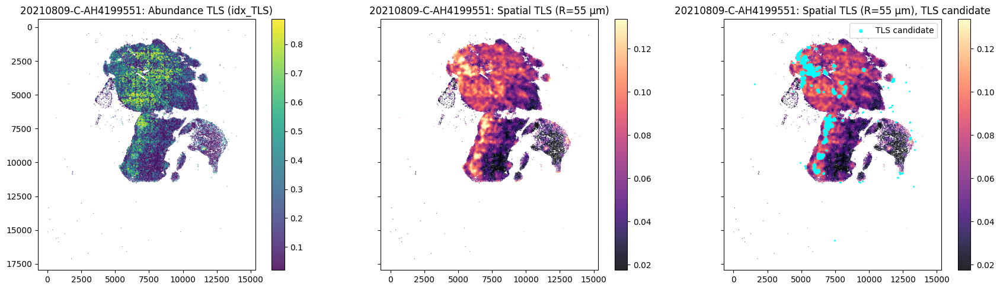

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-C-AH4199551_SRI_abundance_vs_spatial.pdf


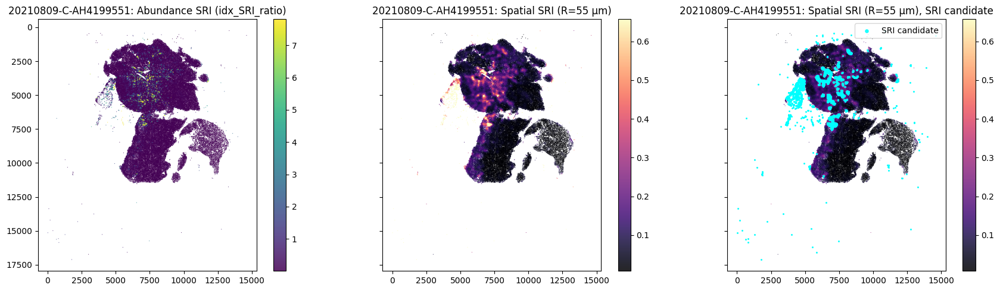

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-C-AH4199551_TNI_abundance_vs_spatial.pdf


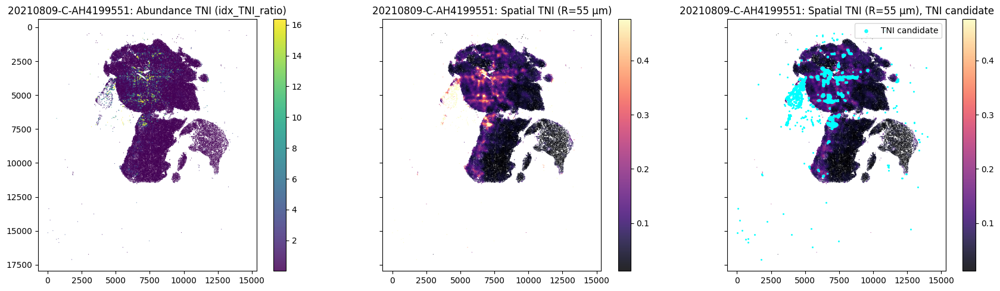

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-D-AJ3037946_TLS_abundance_vs_spatial.pdf


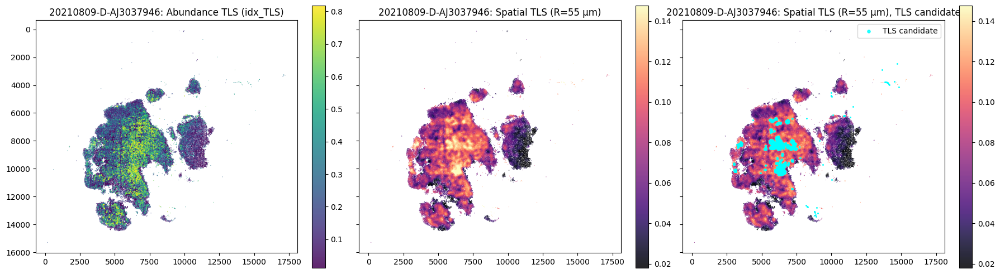

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-D-AJ3037946_SRI_abundance_vs_spatial.pdf


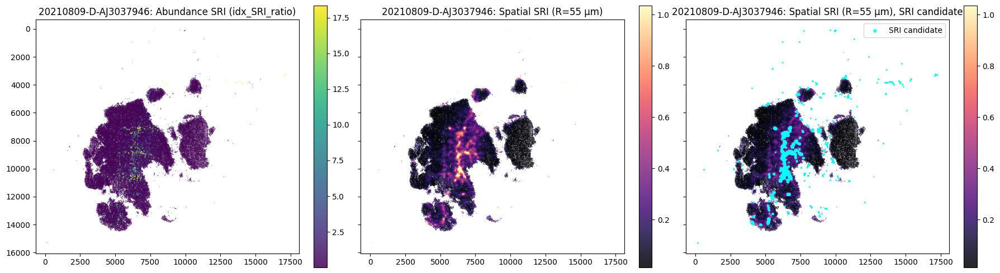

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A2_bestmlp_paired_v2_seed42_prob0.40/figures/20210809-D-AJ3037946_TNI_abundance_vs_spatial.pdf


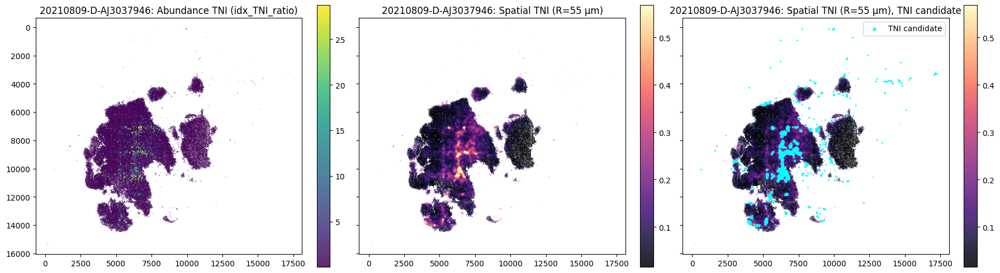

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)


def tls_score_row(df, sample: str) -> dict:
    """Quantify abundance TLS vs spatial TLS on the same nuclei."""
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }


quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
tls_quant = pd.DataFrame(quant_rows)
tls_quant_path = fig_dir / "tls_score_summary.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in niche_frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
        candidate_size=1.2,
        save_path=None,
    )
    if SAVE_FIGURES:
        save_figure(fig, fig_dir / f"{sample}_TLS_abundance_vs_spatial.png")
    display(fig)
    plt.close(fig)

    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            use_entropy=False,
            split_spatial_candidates=True,
            score_name=tag,
            dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
            candidate_size=1.2,
            save_path=None,
        )
        if SAVE_FIGURES:
            save_figure(fig, fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png")
        display(fig)
        plt.close(fig)
